# Практична робота 11. Числові характеристики випадкової величини; закон великих чисел і ЦГТ симуляцією

**Виконав:** Maksym SHmelov  
**Група:** IT41  
**Варіант:** 2 — Львів  
**Параметр експоненційного розподілу:** λ = 0.25 подій/хв  
**Теоретичне середнє:** E[X] = 1/λ = 4 хв.

**Мета:** за допомогою симуляції перевірити закон великих чисел, побачити центральну граничну теорему на скошеному експоненційному розподілі та порівняти теоретичну і виміряну стандартні похибки.

Усі значення часу очікування є навчальною симуляцією, а не реальними даними служби підтримки.

## Крок 1. Імпорт бібліотек і параметри свого варіанта

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 55
plt.rcParams["savefig.dpi"] = 55

VARIANT = 2
CITY = "Львів"
LAMBDA = 0.25  # подій за хвилину
TRUE_MEAN = 1 / LAMBDA
TRUE_STD = 1 / LAMBDA  # для експоненційного розподілу σ = 1/λ

# Один генератор із фіксованим seed для відтворюваності всіх симуляцій.
rng = np.random.default_rng(VARIANT)

print(f"Варіант: {VARIANT} — {CITY}")
print(f"λ = {LAMBDA} подій/хв")
print(f"Теоретичне середнє E[X] = 1/λ = {TRUE_MEAN:.2f} хв")
print(f"Теоретичне стандартне відхилення σ = {TRUE_STD:.2f} хв")

Варіант: 2 — Львів
λ = 0.25 подій/хв
Теоретичне середнє E[X] = 1/λ = 4.00 хв
Теоретичне стандартне відхилення σ = 4.00 хв


## Приклад: демонстрація на часі між покупками

Спершу відтворимо коротку демонстрацію з умови на іншому наборі параметрів (λ = 0.4). Вона показує, як середнє вибірки змінюється зі збільшенням розміру вибірки та як виглядає розподіл повторних середніх.

In [2]:
rng_demo = np.random.default_rng(1)
lam_demo = 0.4
true_mean_demo = 1 / lam_demo

for n_demo in [5, 50, 5_000]:
    sample_demo = rng_demo.exponential(scale=1 / lam_demo, size=n_demo)
    print(f"n={n_demo:>5}: x̄={sample_demo.mean():.4f}, |x̄ - E[X]|={abs(sample_demo.mean() - true_mean_demo):.4f}")

n_repeats_demo = 10_000
means_demo_10 = rng_demo.exponential(scale=1 / lam_demo, size=(n_repeats_demo, 10)).mean(axis=1)
means_demo_200 = rng_demo.exponential(scale=1 / lam_demo, size=(n_repeats_demo, 200)).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8))
axes[0].hist(means_demo_10, bins=40, density=True, edgecolor="white", alpha=0.8)
axes[0].set_title(f"Демонстрація: n=10, std={means_demo_10.std():.3f}")
axes[0].set_xlabel("Вибіркове середнє")
axes[0].set_ylabel("Густина")
axes[1].hist(means_demo_200, bins=40, density=True, edgecolor="white", alpha=0.8)
axes[1].set_title(f"Демонстрація: n=200, std={means_demo_200.std():.3f}")
axes[1].set_xlabel("Вибіркове середнє")
plt.tight_layout()
plt.show()

se_demo_theoretical = true_mean_demo / np.sqrt(200)
print(f"SE теоретична (n=200): {se_demo_theoretical:.4f}")
print(f"SE виміряна симуляцією (n=200): {means_demo_200.std():.4f}")

n=    5: x̄=3.6194, |x̄ - E[X]|=1.1194
n=   50: x̄=2.7905, |x̄ - E[X]|=0.2905
n= 5000: x̄=2.4833, |x̄ - E[X]|=0.0167


SE теоретична (n=200): 0.1768
SE виміряна симуляцією (n=200): 0.1781


## Завдання 1. Перевірка закону великих чисел

Для варіанта 2 використовується експоненційний розподіл із λ = 0.25. Його теоретичне середнє дорівнює 4 хв. Згенеруємо одну вибірку для кожного n та обчислимо вибіркове середнє й абсолютну похибку.

In [3]:
sample_sizes_lln = [5, 50, 500, 20_000]
lln_results = []

for n in sample_sizes_lln:
    sample = rng.exponential(scale=1 / LAMBDA, size=n)
    sample_mean = sample.mean()
    abs_error = abs(sample_mean - TRUE_MEAN)
    lln_results.append({
        "n": n,
        "Вибіркове середнє (хв)": sample_mean,
        "Абсолютна різниця (хв)": abs_error
    })

lln_df = pd.DataFrame(lln_results)
print(lln_df.to_string(index=False, formatters={
    "Вибіркове середнє (хв)": lambda x: f"{x:.4f}",
    "Абсолютна різниця (хв)": lambda x: f"{x:.4f}"
}))

    n Вибіркове середнє (хв) Абсолютна різниця (хв)
    5                 2.2262                 1.7738
   50                 3.7819                 0.2181
  500                 3.6279                 0.3721
20000                 3.9786                 0.0214


**Письмове спостереження:** зі збільшенням n вибіркове середнє зазвичай наближається до теоретичних 4 хвилин, а абсолютна різниця загалом зменшується. Водночас вона не зобов'язана спадати строго на кожному наступному кроці: кожна вибірка випадкова, тому для окремих n похибка може тимчасово збільшитися. Закон великих чисел стверджує збіжність середнього до математичного сподівання при зростанні n, а не монотонне зменшення похибки в кожній конкретній симуляції.

## Завдання 2. Вибірковий розподіл середнього для двох n

Для кожного розміру n згенеруємо 10 000 незалежних вибірок. Кожен рядок матриці — окрема вибірка, а `mean(axis=1)` повертає 10 000 значень вибіркового середнього.

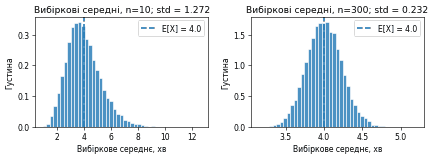

Для n=10: середнє x̄ = 3.9983, std = 1.2724
Для n=300: середнє x̄ = 4.0003, std = 0.2323


In [4]:
n_repeats = 10_000

# Матриці мають форму (кількість повторів, розмір однієї вибірки).
samples_n10 = rng.exponential(scale=1 / LAMBDA, size=(n_repeats, 10))
sample_means_n10 = samples_n10.mean(axis=1)

samples_n300 = rng.exponential(scale=1 / LAMBDA, size=(n_repeats, 300))
sample_means_n300 = samples_n300.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].hist(sample_means_n10, bins=45, density=True, edgecolor="white", alpha=0.8)
axes[0].axvline(TRUE_MEAN, linestyle="--", linewidth=2, label=f"E[X] = {TRUE_MEAN:.1f}")
axes[0].set_title(f"Вибіркові середні, n=10; std = {sample_means_n10.std():.3f}")
axes[0].set_xlabel("Вибіркове середнє, хв")
axes[0].set_ylabel("Густина")
axes[0].legend()

axes[1].hist(sample_means_n300, bins=45, density=True, edgecolor="white", alpha=0.8)
axes[1].axvline(TRUE_MEAN, linestyle="--", linewidth=2, label=f"E[X] = {TRUE_MEAN:.1f}")
axes[1].set_title(f"Вибіркові середні, n=300; std = {sample_means_n300.std():.3f}")
axes[1].set_xlabel("Вибіркове середнє, хв")
axes[1].set_ylabel("Густина")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Для n=10: середнє x̄ = {sample_means_n10.mean():.4f}, std = {sample_means_n10.std():.4f}")
print(f"Для n=300: середнє x̄ = {sample_means_n300.mean():.4f}, std = {sample_means_n300.std():.4f}")

**Письмове порівняння:** для n = 10 розподіл вибіркових середніх ще помітно скошений вправо, хоча він уже симетричніший за вихідний експоненційний розподіл. Для n = 300 гістограма значно ближча до дзвоноподібної та симетричної форми. Це ілюструє центральну граничну теорему: за достатньо великого розміру вибірки розподіл середніх наближається до нормального, навіть якщо окремі спостереження мають скошений розподіл.

## Завдання 3. Стандартна похибка: теорія проти симуляції

Для експоненційного розподілу середнє та стандартне відхилення дорівнюють 1/λ = 4 хв. Тому теоретична стандартна похибка середнього має вигляд `SE = (1/λ) / sqrt(n)`. Порівняємо її зі стандартним відхиленням симульованих середніх для кожного n.

In [5]:
n_values_se = [10, 30, 100, 300]

# Для n=10 та n=300 використовуємо повторні середні із Завдання 2.
sample_means_by_n = {
    10: sample_means_n10,
    300: sample_means_n300
}

# Генеруємо 10 000 повторів для n=30 та n=100.
for n in [30, 100]:
    repeated_samples = rng.exponential(scale=1 / LAMBDA, size=(n_repeats, n))
    sample_means_by_n[n] = repeated_samples.mean(axis=1)

se_rows = []
for n in n_values_se:
    theoretical_se = TRUE_STD / np.sqrt(n)
    simulated_std = sample_means_by_n[n].std()
    se_rows.append({
        "n": n,
        "Теоретична SE (хв)": theoretical_se,
        "Виміряна std (хв)": simulated_std,
        "Абсолютна різниця (хв)": abs(simulated_std - theoretical_se)
    })

se_df = pd.DataFrame(se_rows)
print(se_df.to_string(index=False, formatters={
    "Теоретична SE (хв)": lambda x: f"{x:.4f}",
    "Виміряна std (хв)": lambda x: f"{x:.4f}",
    "Абсолютна різниця (хв)": lambda x: f"{x:.4f}"
}))

  n Теоретична SE (хв) Виміряна std (хв) Абсолютна різниця (хв)
 10             1.2649            1.2724                 0.0074
 30             0.7303            0.7267                 0.0036
100             0.4000            0.3994                 0.0006
300             0.2309            0.2323                 0.0014


**Письмова оцінка:** теоретичні значення SE та виміряні стандартні відхилення симульованих середніх мають бути близькими. Невелика різниця між ними пояснюється скінченною кількістю повторів (10 000) і випадковою мінливістю симуляції. Зі збільшенням n обидва показники зменшуються приблизно за законом 1/√n.

## Завдання 4. Закон убуваючої віддачі

Порівняємо стандартну похибку для n = 25 та n = 100. Другий розмір вибірки вчетверо більший за перший.

In [6]:
se_n25 = TRUE_STD / np.sqrt(25)
se_n100 = TRUE_STD / np.sqrt(100)
ratio = se_n25 / se_n100

print(f"SE для n=25:  {se_n25:.4f} хв")
print(f"SE для n=100: {se_n100:.4f} хв")
print(f"Відношення SE(25) / SE(100): {ratio:.2f}")

SE для n=25:  0.8000 хв
SE для n=100: 0.4000 хв
Відношення SE(25) / SE(100): 2.00


**Пояснення:** для n = 25 стандартна похибка дорівнює 0.8 хв, а для n = 100 — 0.4 хв. Коли розмір вибірки збільшився вчетверо, стандартна похибка зменшилася вдвічі, а не вчетверо. Це випливає з формули `SE = σ / √n`: корінь квадратний із 4n дорівнює 2√n. Отже, для зменшення похибки вдвічі потрібно приблизно вчетверо більше спостережень.

## Завдання 5. Вплив кількості повторів n_repeats на якість симуляції (додатково)

Повторимо симуляцію для n = 10, але лише з 50 повторними вибірками замість 10 000. Розмір кожної окремої вибірки залишається тим самим — 10.

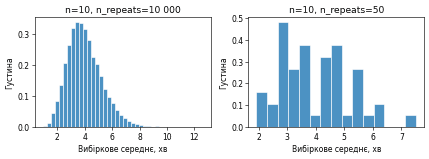

Середнє 10 000 повторів: 3.9983 хв
Середнє 50 повторів: 3.9975 хв


In [7]:
n_repeats_small = 50
samples_n10_small_repeats = rng.exponential(
    scale=1 / LAMBDA,
    size=(n_repeats_small, 10)
)
sample_means_n10_small_repeats = samples_n10_small_repeats.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].hist(sample_means_n10, bins=40, density=True, edgecolor="white", alpha=0.8)
axes[0].set_title("n=10, n_repeats=10 000")
axes[0].set_xlabel("Вибіркове середнє, хв")
axes[0].set_ylabel("Густина")

axes[1].hist(sample_means_n10_small_repeats, bins=15, density=True, edgecolor="white", alpha=0.8)
axes[1].set_title("n=10, n_repeats=50")
axes[1].set_xlabel("Вибіркове середнє, хв")
axes[1].set_ylabel("Густина")
plt.tight_layout()
plt.show()

print(f"Середнє 10 000 повторів: {sample_means_n10.mean():.4f} хв")
print(f"Середнє 50 повторів: {sample_means_n10_small_repeats.mean():.4f} хв")

**Пояснення:** при 10 000 повторів гістограма вибіркового розподілу середнього виходить значно гладшою, оскільки в ній багато реалізацій x̄. При 50 повторах стовпці гістограми нерівні та сильніше залежать від випадкового набору значень. Саме `n_repeats` визначає, скільки середніх потрапить у гістограму, а отже — наскільки детально вона відображає форму вибіркового розподілу. Параметр `n` визначає розмір кожної окремої вибірки та впливає на форму й розкид самого розподілу середніх, але не на кількість значень у гістограмі.

## Письмові відповіді на контрольні питання

**1. Чим відрізняються закон великих чисел і центральна гранична теорема?**

Закон великих чисел відповідає на питання, **куди прямує вибіркове середнє**: зі збільшенням кількості спостережень воно наближається до теоретичного математичного сподівання. Центральна гранична теорема відповідає на питання, **яку форму й розкид має розподіл вибіркового середнього**: за достатньо великого n цей розподіл наближається до нормального, а його стандартна похибка зменшується як σ/√n.

**2. Чому вихідний розподіл обрано сильно скошеним, а не нормальним?**

Експоненційний розподіл часу очікування має виражену правосторонню асиметрію. Це дає змогу побачити, як середні багатьох вибірок поступово набувають приблизно нормальної, симетричної форми. Якби вихідні дані відразу мали нормальний розподіл, центральну граничну теорему було б менш наочно продемонструвати: середні також були б нормальними, але перехід від скошеної форми до дзвоноподібної не був би видимим.

**3. Чому стандартна похибка зменшується пропорційно √n, а не n? Скільки спостережень потрібно для зменшення похибки вдвічі?**

Стандартна похибка середнього дорівнює `SE = σ/√n`, оскільки усереднення незалежних спостережень зменшує дисперсію середнього у n разів, а стандартне відхилення є квадратним коренем із дисперсії. Тому для зменшення стандартної похибки вдвічі потрібно збільшити n у чотири рази: `√(4n) = 2√n`. Наприклад, перехід від 25 до 100 спостережень зменшує SE з 0.8 до 0.4 хв.

## Висновок

Під час практичної роботи для варіанта 2 (Львів, λ = 0.25) було змодельовано експоненційний час очікування з теоретичним середнім 4 хв. Перевірено закон великих чисел на вибірках різного розміру, а також центральну граничну теорему через 10 000 повторних вибірок із n = 10 та n = 300. Порівняно теоретичну стандартну похибку з результатами симуляції, досліджено зменшення SE при збільшенні n і вплив кількості повторів на гладкість гістограми.